### rebuilt lab2

adapted from Appendix C.2, not numbered problems

In [1]:
import sqlite3

con = sqlite3.connect(":memory:")
print("Connected to in-memory SQLite database")

Connected to in-memory SQLite database


In [2]:
con.execute("""
CREATE TABLE customers (
    id      INTEGER PRIMARY KEY,
    name    TEXT NOT NULL,
    city    TEXT NOT NULL,
    balance REAL NOT NULL
)
""")
print("Table created")

Table created


### dialect awareness: MySQL to SQLite

SQLite does not enforce the length and precision limits of MySQL types like VARCHAR(50) and DECIMAL(10,2), so I used TEXT and REAL instead. REAL is floating point, so a production database would use DECIMAL in MySQL for money. MySQL uses AUTO_INCREMENT to generate ids. In SQLite, declaring a column INTEGER PRIMARY KEY does the same job: if you leave id out of an INSERT, SQLite assigns the next number automatically.

In [3]:
rows = [
    (1, "Ava Thompson",  "Seattle",   1250.50),
    (2, "Liam Carter",   "Portland",   980.00),
    (3, "Sofia Ramirez", "Austin",    2310.75),
    (4, "Noah Kim",      "San Diego",  455.20),
    (5, "Emma Dubois",   "Chicago",   1789.99),
    (6, "Oliver Singh",  "Denver",     620.40),
    (7, "Mia Johansson", "Boston",    3050.00),
    (8, "Ethan Okafor",  "Atlanta",    875.65),
    (9, "Chloe Nguyen",  "Phoenix",   1432.10),
    (10, "Lucas Silva",  "Miami",      299.95),
]

for r in rows:
    con.execute(
        "INSERT INTO customers (id, name, city, balance) VALUES (?, ?, ?, ?)", r
    )
con.commit()
print(f"Inserted {len(rows)} rows")

Inserted 10 rows


In [4]:
cur = con.execute("SELECT * FROM customers")
print([d[0] for d in cur.description])
for row in cur.fetchall():
    print(row)

['id', 'name', 'city', 'balance']
(1, 'Ava Thompson', 'Seattle', 1250.5)
(2, 'Liam Carter', 'Portland', 980.0)
(3, 'Sofia Ramirez', 'Austin', 2310.75)
(4, 'Noah Kim', 'San Diego', 455.2)
(5, 'Emma Dubois', 'Chicago', 1789.99)
(6, 'Oliver Singh', 'Denver', 620.4)
(7, 'Mia Johansson', 'Boston', 3050.0)
(8, 'Ethan Okafor', 'Atlanta', 875.65)
(9, 'Chloe Nguyen', 'Phoenix', 1432.1)
(10, 'Lucas Silva', 'Miami', 299.95)


In [5]:
print("Row count:", con.execute("SELECT COUNT(*) FROM customers").fetchone()[0])

Row count: 10


### lab 3 below

## query 1: filtered retrieval with WHERE and ORDER BY

WHERE only keeps rows that match a condition. ORDER BY ... DESC sorts what is left highest to lowest. This query finds customers with balances above $1,000 sorted from highest to lowest. ? is a placeholder that passes the threshold as a parameter instead of pasting it into the SQL string.

In [6]:
q1 = "SELECT id, name, city, balance FROM customers WHERE balance > ? ORDER BY balance DESC"
cur = con.execute(q1, (1000,))
print([d[0] for d in cur.description])
for row in cur.fetchall():
    print(row)

['id', 'name', 'city', 'balance']
(7, 'Mia Johansson', 'Boston', 3050.0)
(3, 'Sofia Ramirez', 'Austin', 2310.75)
(5, 'Emma Dubois', 'Chicago', 1789.99)
(9, 'Chloe Nguyen', 'Phoenix', 1432.1)
(1, 'Ava Thompson', 'Seattle', 1250.5)


## query 2: text search with LIKE and wildcards

% matches any run of characters (including none), so '%an%' finds names with "an" anywhere in them. SQLite's LIKE is not case sensitive for ASCII letters, so '%AN%' would return the same results. MySQL's default collation behaves the same way.

In [7]:
q2 = "SELECT id, name, city, balance FROM customers WHERE name LIKE ? ORDER BY name"
cur = con.execute(q2, ("%an%",))
print([d[0] for d in cur.description])
for row in cur.fetchall():
    print(row)

['id', 'name', 'city', 'balance']
(8, 'Ethan Okafor', 'Atlanta', 875.65)
(7, 'Mia Johansson', 'Boston', 3050.0)


### Check:
Ethan Okafor (Eth**an**) and Mia Johansson (Joh**an**sson) are the only names that contain "an". Looking though the other eight names names I can confirm that the two rows returned are the correct ones.

## query 3: a wildcard at one end, plus a sort

Because the wildcard sits at the end 'S%' only matches values that start with S. This pulls customers in cities beginning with S and sorts them by balance.

In [8]:
q3 = "SELECT id, name, city, balance FROM customers WHERE city LIKE ? ORDER BY balance DESC"
cur = con.execute(q3, ("S%",))
print([d[0] for d in cur.description])
for row in cur.fetchall():
    print(row)

['id', 'name', 'city', 'balance']
(1, 'Ava Thompson', 'Seattle', 1250.5)
(4, 'Noah Kim', 'San Diego', 455.2)


## query to chart: the round trip

pd.read_sql runs a query and hands back a DataFrame that matplotlib can chart directly. I'm charting Query 1. The chart shows the customers with balances above $1,000. Because the query already sorted the rows, the bars also come out in order.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_sql(q1, con, params=(1000,))
df

,id,name,city,balance
0,7,Mia Johansson,Boston,3050.00
1,3,Sofia Ramirez,Austin,2310.75
2,5,Emma Dubois,Chicago,1789.99
3,9,Chloe Nguyen,Phoenix,1432.10
4,1,Ava Thompson,Seattle,1250.50


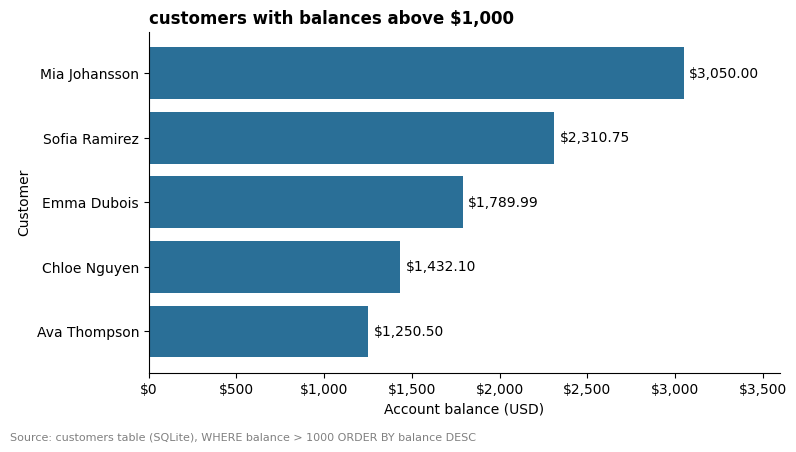

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(df["name"], df["balance"], color="#2a6f97")
ax.invert_yaxis()  # largest balance on top, matching ORDER BY balance DESC
ax.bar_label(bars, labels=[f"${b:,.2f}" for b in df["balance"]], padding=4)

ax.set_title("customers with balances above $1,000", loc="left", fontweight="bold")
ax.set_xlabel("Account balance (USD)")
ax.set_ylabel("Customer")
ax.set_xlim(0, df["balance"].max() * 1.18)
ax.xaxis.set_major_formatter(lambda x, _: f"${x:,.0f}")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source: customers table (SQLite), WHERE balance > 1000 ORDER BY balance DESC",
         fontsize=8, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()